# MS-32 — Per-class Pseudo-label Analysis

H5: Does one global threshold give different terrain classes unequal or unreliable pseudo-labels?

Use the **MS-20 supervised model as a proxy**. Coverage is measured on unlabeled pixels (`255`); precision is measured only on labeled pixels.

In [1]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

RUN_NAME = "baseline_r50_short_1xHeadLR"
SPLIT = "val"
CHECKPOINT = None  # Set a path here if best.pth is not in runs/RUN_NAME/
NUM_BINS = 50
HARD_THRESHOLD = 0.5
SOFT_THRESHOLD = 0.9

ROOT = Path.cwd().resolve()
while not (ROOT / "data.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "data.py").exists():
    raise FileNotFoundError("Run this notebook inside the project folder")
sys.path.insert(0, str(ROOT))

from data import CLASSES, NUM_CLASSES, IGNORE_INDEX, DATA_ROOT, get_dataloaders
from models import build_model

if CHECKPOINT is None:
    checkpoint_path = ROOT / "runs" / RUN_NAME / "best.pth"
else:
    checkpoint_path = Path(CHECKPOINT).expanduser()
    if not checkpoint_path.is_absolute():
        checkpoint_path = ROOT / checkpoint_path

if not checkpoint_path.exists():
    raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

data_root = Path(os.environ.get("S5MARS_ROOT", DATA_ROOT)).expanduser()
out_dir = ROOT / "analysis" / "results" / "MS-32" / RUN_NAME / SPLIT
out_dir.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
# print("Checkpoint:", checkpoint_path)
# print("Data:", data_root)
# print("Output:", out_dir)

In [ ]:
ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
model = build_model({**ckpt.get("model_cfg", {}), "pretrained": False}).to(device)
model.load_state_dict(ckpt["model"])
model.eval()

_, val_loader, test_loader = get_dataloaders(eval_batch=1, num_workers=0, root=str(data_root))
loader = val_loader if SPLIT == "val" else test_loader
print("Images:", len(loader.dataset))

Images: 200


In [ ]:
counts = {}
names = ["unlabeled_predicted", "unlabeled_hard", "unlabeled_soft", "unlabeled_both", "unlabeled_high", "labeled_hard", "labeled_hard_correct", "labeled_high", "labeled_high_correct"]
for name in names:
    counts[name] = np.zeros(NUM_CLASSES, dtype=np.int64)

hist = np.zeros((NUM_CLASSES, NUM_BINS), dtype=np.int64)

with torch.no_grad():
    for batch_idx, (images, labels, ids) in enumerate(loader):
        logits = model(images.to(device))
        confidence, prediction = torch.softmax(logits.float(), dim=1).max(dim=1)

        conf = confidence.cpu().numpy().ravel()
        pred = prediction.cpu().numpy().ravel()
        gt = labels.numpy().ravel()

        unlabeled = gt == IGNORE_INDEX
        labeled = gt != IGNORE_INDEX
        hard = conf > HARD_THRESHOLD
        soft = conf < SOFT_THRESHOLD
        high = conf > SOFT_THRESHOLD
        correct = pred == gt

        for c in range(NUM_CLASSES):
            u = unlabeled & (pred == c)
            l = labeled & (pred == c)

            counts["unlabeled_predicted"][c] += u.sum()
            counts["unlabeled_hard"][c] += (u & hard).sum()
            counts["unlabeled_soft"][c] += (u & soft).sum()
            counts["unlabeled_both"][c] += (u & hard & soft).sum()
            counts["unlabeled_high"][c] += (u & high).sum()
            counts["labeled_hard"][c] += (l & hard).sum()
            counts["labeled_hard_correct"][c] += (l & hard & correct).sum()
            counts["labeled_high"][c] += (l & high).sum()
            counts["labeled_high_correct"][c] += (l & high & correct).sum()
            hist[c] += np.histogram(conf[u], bins=NUM_BINS, range=(0, 1))[0]

        if (batch_idx + 1) % 25 == 0 or batch_idx + 1 == len(loader):
            print(f"{batch_idx + 1}/{len(loader)} batches")

assert hist.sum() == counts["unlabeled_predicted"].sum()

25/200 batches
50/200 batches
75/200 batches
100/200 batches
125/200 batches
150/200 batches
175/200 batches
200/200 batches


In [4]:
def percent(a, b):
    return 100 * np.divide(a, b, out=np.full(NUM_CLASSES, np.nan), where=b != 0)

u = counts["unlabeled_predicted"]
h = counts["unlabeled_hard"]

results = pd.DataFrame({
    "class": CLASSES,
    "unlabeled_predicted_px": u,
    "predicted_share_pct": percent(u, np.full(NUM_CLASSES, u.sum())),
    "hard_px": h,
    "hard_coverage_pct": percent(h, u),
    "hard_share_pct": percent(h, np.full(NUM_CLASSES, h.sum())),
    "soft_coverage_pct": percent(counts["unlabeled_soft"], u),
    "overlap_coverage_pct": percent(counts["unlabeled_both"], u),
    "over_0_9_coverage_pct": percent(counts["unlabeled_high"], u),
    "labeled_hard_px": counts["labeled_hard"],
    "precision_over_0_5_pct": percent(counts["labeled_hard_correct"], counts["labeled_hard"]),
    "labeled_over_0_9_px": counts["labeled_high"],
    "precision_over_0_9_pct": percent(counts["labeled_high_correct"], counts["labeled_high"]),
})

display(results.round(2))

,class,unlabeled_predicted_px,predicted_share_pct,hard_px,hard_coverage_pct,hard_share_pct,soft_coverage_pct,overlap_coverage_pct,over_0_9_coverage_pct,labeled_hard_px,precision_over_0_5_pct,labeled_over_0_9_px,precision_over_0_9_pct
0,sky,2752,0.00,2220,80.67,0.00,80.63,61.30,19.37,9944328,99.45,9520730,99.93
1,ridge,115330,0.11,94528,81.96,0.09,91.25,73.22,8.75,16092370,95.02,14387763,98.70
2,soil,50254644,47.84,49351234,98.20,47.98,36.31,34.51,63.69,13177128,93.10,9854602,98.98
3,sand,2637983,2.51,2393769,90.74,2.33,73.72,64.46,26.28,5924356,89.46,4155911,99.38
4,bedrock,50974539,48.52,50093481,98.27,48.70,36.18,34.45,63.82,56849867,94.95,47188635,98.97
5,rock,384832,0.37,310688,80.73,0.30,99.98,80.71,0.02,1563689,85.88,6595,100.00
6,rover,71851,0.07,51892,72.22,0.05,76.51,48.74,23.49,223112,98.49,169658,99.91
7,trace,602984,0.57,561745,93.16,0.55,86.94,80.10,13.06,340374,66.46,134036,78.31
8,hole,3650,0.00,471,12.90,0.00,100.00,12.90,0.00,86742,83.60,13065,99.72


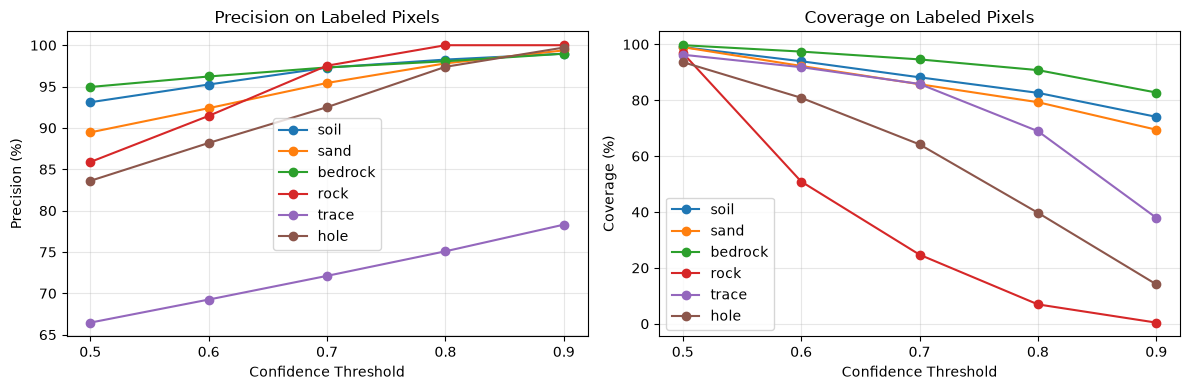

,class,threshold,precision,coverage,selected_pixels
0,sky,0.5,99.45,99.96,9944328
1,sky,0.6,99.66,99.07,9855983
2,sky,0.7,99.76,98.39,9788180
3,sky,0.8,99.84,97.58,9707826
4,sky,0.9,99.93,95.70,9520730
5,ridge,0.5,95.02,99.95,16092370
6,ridge,0.6,96.07,98.48,15855017
7,ridge,0.7,97.09,96.42,15524119
8,ridge,0.8,97.86,93.67,15081739
9,ridge,0.9,98.70,89.36,14387763


In [ ]:
# try different thresholds
THRESHOLDS = [0.5, 0.6, 0.7, 0.8, 0.9]
classes_to_plot = ["soil", "sand", "bedrock", "rock", "trace", "hole"]

total = np.zeros((NUM_CLASSES, len(THRESHOLDS)))
correct = np.zeros_like(total)
predicted = np.zeros(NUM_CLASSES)

with torch.no_grad():
    for images, labels, _ in loader:
        logits = model(images.to(device))
        conf, pred = torch.softmax(logits.float(), dim=1).max(dim=1)
        conf = conf.cpu().numpy()
        pred = pred.cpu().numpy()
        gt = labels.numpy()
        for c in range(NUM_CLASSES):
            mask = (gt != IGNORE_INDEX) & (pred == c)
            predicted[c] += mask.sum()

            for j, threshold in enumerate(THRESHOLDS):
                selected = mask & (conf > threshold)
                total[c, j] += selected.sum()
                correct[c, j] += (selected & (pred == gt)).sum()

precision = 100 * np.divide(correct, total, out=np.full_like(total, np.nan), where=total > 0)
coverage = 100 * np.divide(total, predicted[:, None], out=np.full_like(total, np.nan), where=predicted[:, None] > 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name in classes_to_plot:
    c = CLASSES.index(name)
    axes[0].plot(THRESHOLDS, precision[c], marker="o", label=name)
    axes[1].plot(THRESHOLDS, coverage[c], marker="o", label=name)

axes[0].set_title("Precision on Labeled Pixels")
axes[0].set_ylabel("Precision (%)")
axes[1].set_title("Coverage on Labeled Pixels")
axes[1].set_ylabel("Coverage (%)")

for ax in axes:
    ax.set_xlabel("Confidence Threshold")
    ax.set_xticks(THRESHOLDS)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(out_dir / "confidence_precision_coverage.png", dpi=200)
plt.show()

threshold_df = pd.DataFrame([
    {
        "class": name,
        "threshold": threshold,
        "precision": precision[c, j],
        "coverage": coverage[c, j],
        "selected_pixels": int(total[c, j])
    }
    for c, name in enumerate(CLASSES)
    for j, threshold in enumerate(THRESHOLDS)
])

display(threshold_df.round(2))
threshold_df.to_csv(out_dir / "threshold_analysis.csv", index=False)

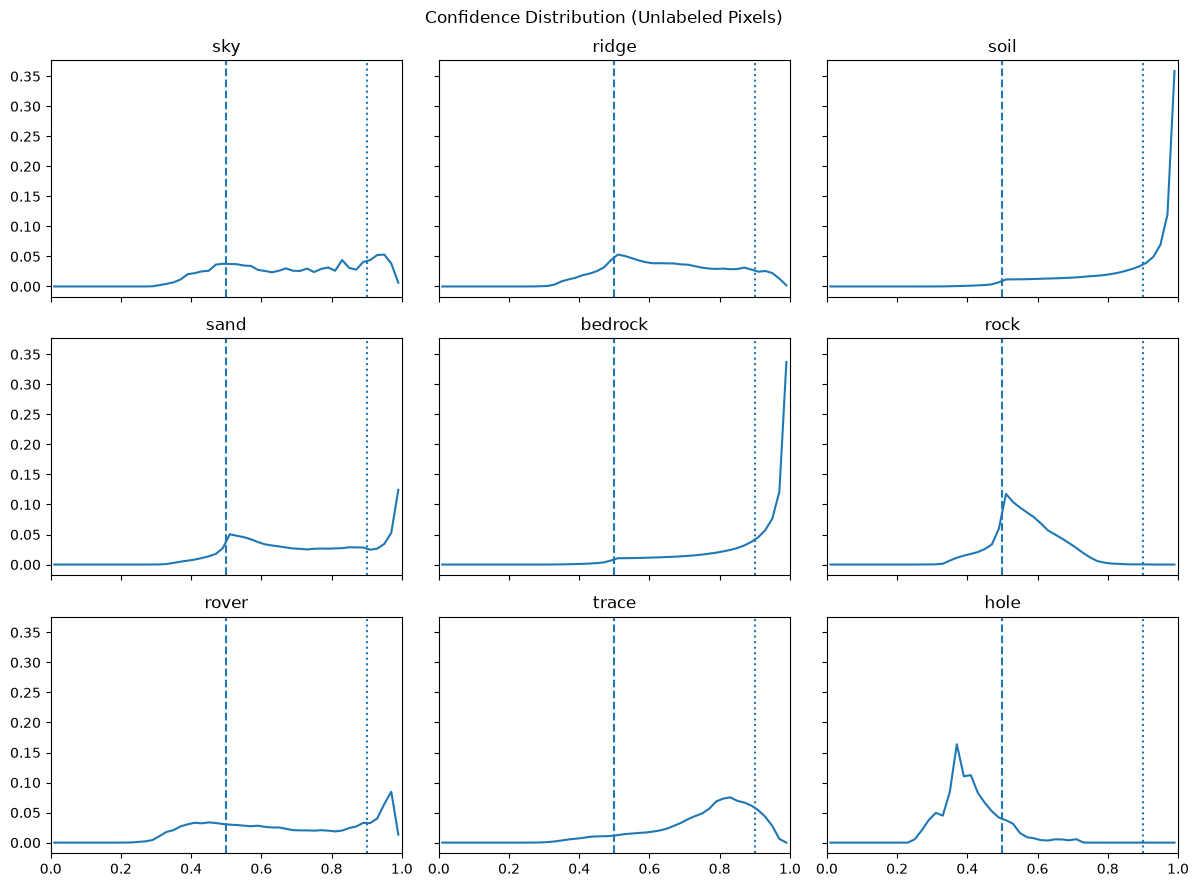

In [6]:
edges = np.linspace(0, 1, NUM_BINS + 1)
centers = (edges[:-1] + edges[1:]) / 2

fig, axes = plt.subplots(3, 3, figsize=(12, 9), sharex=True, sharey=True)
for c, ax in enumerate(axes.flat):
    if hist[c].sum() > 0:
        ax.plot(centers, hist[c] / hist[c].sum())
    ax.axvline(HARD_THRESHOLD, linestyle="--")
    ax.axvline(SOFT_THRESHOLD, linestyle=":")
    ax.set_title(CLASSES[c])
    ax.set_xlim(0, 1)
fig.suptitle("Confidence Distribution (Unlabeled Pixels)")
fig.tight_layout()
fig.savefig(out_dir / "confidence_distribution.png", dpi=200)
plt.show()

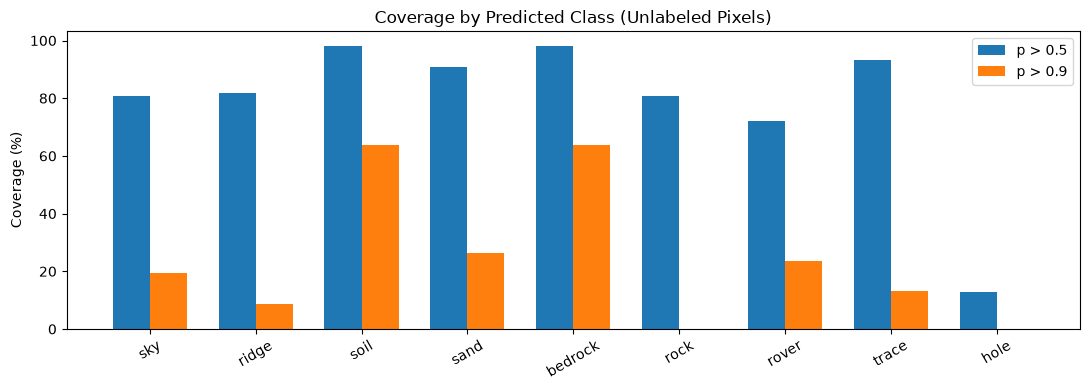

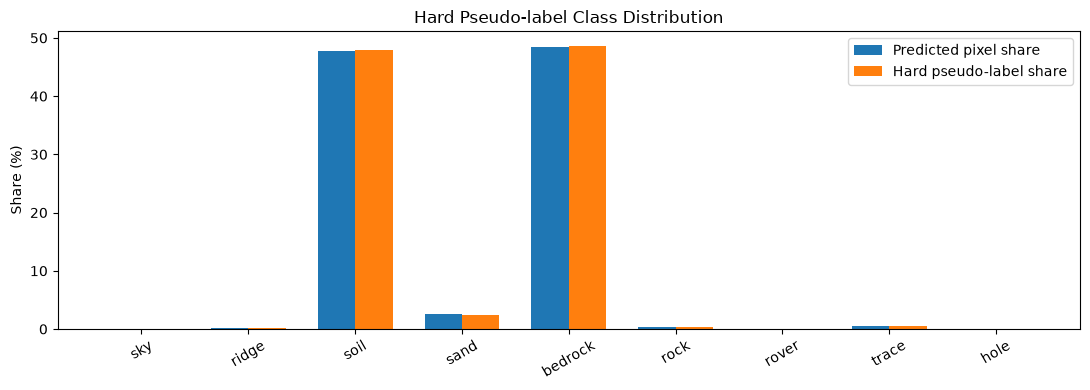

In [7]:
x = np.arange(NUM_CLASSES)
width = 0.35

plt.figure(figsize=(11, 4))
plt.bar(x - width/2, results["hard_coverage_pct"], width, label="p > 0.5")
plt.bar(x + width/2, results["over_0_9_coverage_pct"], width, label="p > 0.9")
plt.xticks(x, CLASSES, rotation=30)
plt.ylabel("Coverage (%)")
plt.title("Coverage by Predicted Class (Unlabeled Pixels)")
plt.legend()
plt.tight_layout()
plt.savefig(out_dir / "hard_label_coverage.png", dpi=200)
plt.show()

plt.figure(figsize=(11, 4))
plt.bar(x - width/2, results["predicted_share_pct"], width, label="Predicted pixel share")
plt.bar(x + width/2, results["hard_share_pct"], width, label="Hard pseudo-label share")
plt.xticks(x, CLASSES, rotation=30)
plt.ylabel("Share (%)")
plt.title("Hard Pseudo-label Class Distribution")
plt.legend()
plt.tight_layout()
plt.savefig(out_dir / "hard_label_class_share.png", dpi=200)
plt.show()

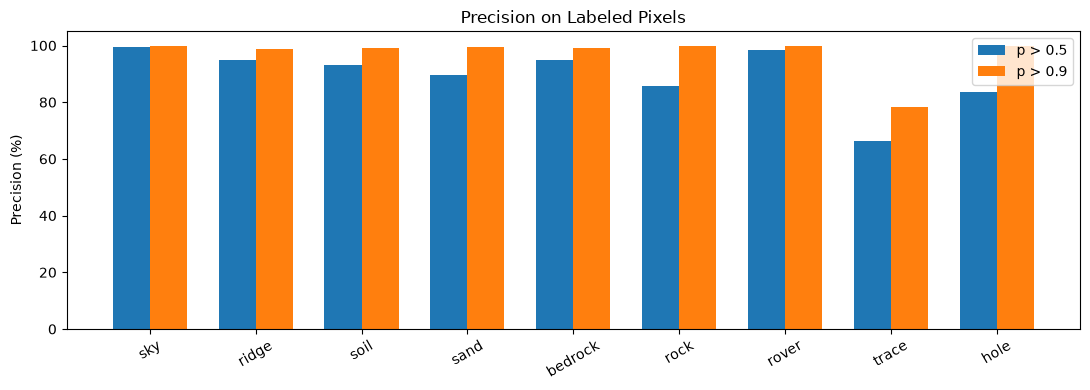

In [8]:
plt.figure(figsize=(11, 4))
plt.bar(x - width/2, results["precision_over_0_5_pct"], width, label="p > 0.5")
plt.bar(x + width/2, results["precision_over_0_9_pct"], width, label="p > 0.9")
plt.xticks(x, CLASSES, rotation=30)
plt.ylabel("Precision (%)")
plt.title("Precision on Labeled Pixels")
plt.legend()
plt.tight_layout()
plt.savefig(out_dir / "pseudo_label_precision.png", dpi=200)
plt.show()

In [9]:
results.to_csv(out_dir / "statistics.csv", index=False)
results.to_json(out_dir / "statistics.json", orient="records", indent=2)
np.savez_compressed(out_dir / "confidence_histograms.npz", bin_edges=edges, unlabeled=hist)

metadata = {
    "run": RUN_NAME,
    "split": SPLIT,
    "checkpoint": str(checkpoint_path),
    "model": "supervised proxy (MS-20)",
    "hard_threshold": HARD_THRESHOLD,
    "soft_threshold": SOFT_THRESHOLD,
    "protocol": "1024 center crop, ImageNet normalization",
    "note": "Precision uses labeled pixels only; unlabeled accuracy is unknown.",
}
with open(out_dir / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

## Conclusion ##

Our analysis reveals substantial class-dependent differences in prediction confidence, pseudo-label coverage, and reliability under global confidence thresholds. On unlabeled pixels, dominant classes such as soil and bedrock achieve over 98% hard-label coverage at a threshold of 0.5, while rock and hole achieve only 80.73% and 12.90%, respectively. The hard pseudo-label distribution is also heavily concentrated in soil and bedrock, suggesting that global thresholding may reinforce the imbalance in pseudo-label supervision.

The confidence-threshold analysis further reveals distinct precision–coverage trade-offs across classes. For example, increasing the threshold from 0.5 to 0.9 improves rock precision from 85.88% to 100%, but reduces its coverage on labeled pixels from 96.89% to only 0.41%. In contrast, soil and bedrock maintain over 74% and 82% coverage, respectively, while achieving approximately 99% precision. Trace remains relatively unreliable even at a threshold of 0.9, reaching only 78.31% precision. These findings suggest that a single global confidence threshold may not provide an appropriate balance between pseudo-label quantity and reliability across different terrain classes.

Overall, these results motivate our proposed class-adaptive confidence thresholds, which aim to account for class-specific confidence distributions and reliability when selecting pseudo-labels. However, this analysis uses a supervised model as a proxy for the EMA teacher, and precision is measured only on labeled pixels. Therefore, the results do not establish pseudo-label accuracy on unlabeled regions or demonstrate the effectiveness of adaptive thresholds. These hypotheses will be evaluated through controlled SSL experiments in MS-33 and MS-34.